# When Does Market Making Pay After Costs and Inventory Risk?
## From causal calibration to execution robustness

This notebook is an executable research tour. It uses the original offline generator and reads saved experiment tables; it never downloads market data automatically. The full methods, execution assumptions, and attribution are in `docs/METHODOLOGY.md`.

The research objective is to understand risk and execution sensitivity, including failures—not to engineer a favorable single backtest.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from dataclasses import replace
from microstructure_mm.synthetic import generate, SyntheticConfig
from microstructure_mm.calibration import calibrate
from microstructure_mm.engine import replay
from microstructure_mm.types import ReplayConfig
from microstructure_mm.policies import Policy
from IPython.display import display, Image
print("Repository:", ROOT.name)

Repository: microstructure-market-making


### 1. Generate once; calibrate before evaluation

Every policy receives the same held-out tape. The first 30 seconds below are training only. The known scheduled session endpoint is permitted; future observations are not.

In [2]:
tape = generate(73021, SyntheticConfig(duration=120))
training = tape.window(0, 30)
evaluation = tape.window(30, 120)
config = ReplayConfig()
fit, diagnostics = calibrate(training, config)
print("Training events:", len(training.events), "Test events:", len(evaluation.events))
print("Variance / second:", round(fit.variance_rate, 4))
print("Depth decay kappa:", round(fit.kappa, 4))
print("Composite optimizer success:", diagnostics["success"])

Training events: 192 Test events: 649
Variance / second: 0.7672
Depth decay kappa: 0.9459
Composite optimizer success: True


### 2. Compare the four fixed policies

Cash P&L is measured after forced closing at the opposite BBO, including taker cost. A policy may sacrifice P&L to lower inventory risk. `record=True` retains every fill for audit.

In [3]:
runs = {policy.value: replay(evaluation, policy, fit, config) for policy in Policy}
comparison = pd.DataFrame([r.summary for r in runs.values()]).set_index("policy")
display(comparison[["net_pnl_ticks_lots", "rms_inventory", "max_abs_inventory", "maker_fills", "liquidation_spread_cost"]].round(3))

,net_pnl_ticks_lots,rms_inventory,max_abs_inventory,maker_fills,liquidation_spread_cost
policy,,,,,
passive,244.997,1.533,4.0,98,5.0
as_fixed,178.998,1.318,3.0,113,2.5
as_adaptive,168.000,0.994,3.0,102,0.0
as_imbalance,109.000,1.104,3.0,94,0.0


### 3. Audit a fill, not just a performance chart

The execution timestamp must exceed activation. Each maker fill is limited by the recorded trade, remaining order size, participation budget, and inventory cap.

In [4]:
fills = runs["as_adaptive"].fills
maker = fills.query("kind == 'maker'")
assert (maker.time > maker.activated).all()
assert (maker["size"] <= config.participation * maker.trade_size + 1e-9).all()
assert (maker.inventory.abs() <= config.max_inventory + 1e-9).all()
display(maker.head(8).round(4))

,time,side,price,size,fee,mid,inventory,cash,activated,submitted,trade_size,kind
0,0.7523,-1,10005,1,0.0,10003.5,-1.0,10005.0,0.05,0.0,56.0,maker
1,1.4441,1,10003,1,0.0,10004.5,0.0,2.0,1.05,1.0,50.0,maker
2,2.2195,-1,10006,1,0.0,10004.5,-1.0,10008.0,2.05,2.0,121.0,maker
3,2.9181,1,10003,1,0.0,10004.5,0.0,5.0,2.05,2.0,50.0,maker
4,3.7671,1,10002,1,0.0,10005.5,1.0,-9997.0,3.05,3.0,60.0,maker
5,3.8216,-1,10005,1,0.0,10005.5,0.0,8.0,3.05,3.0,51.0,maker
6,4.1557,-1,10007,1,0.0,10005.5,-1.0,10015.0,4.05,4.0,74.0,maker
7,5.3993,1,10004,1,0.0,10006.5,0.0,11.0,4.05,4.0,49.0,maker


### 4. The independent unit is a simulated path

The saved full run pairs strategies across 256 independently seeded paths. These intervals do not treat thousands of correlated fills as independent observations.

,policy,baseline,metric,mean_difference,ci_low,ci_high,independent_paths,win_fraction,tie_fraction
0,as_adaptive,passive,net_pnl_ticks_lots,-169.184,-191.440,-145.482,256,0.160,0.0
1,as_fixed,passive,net_pnl_ticks_lots,-142.973,-164.173,-121.191,256,0.191,0.0
2,as_imbalance,passive,net_pnl_ticks_lots,-297.422,-321.202,-274.086,256,0.055,0.0


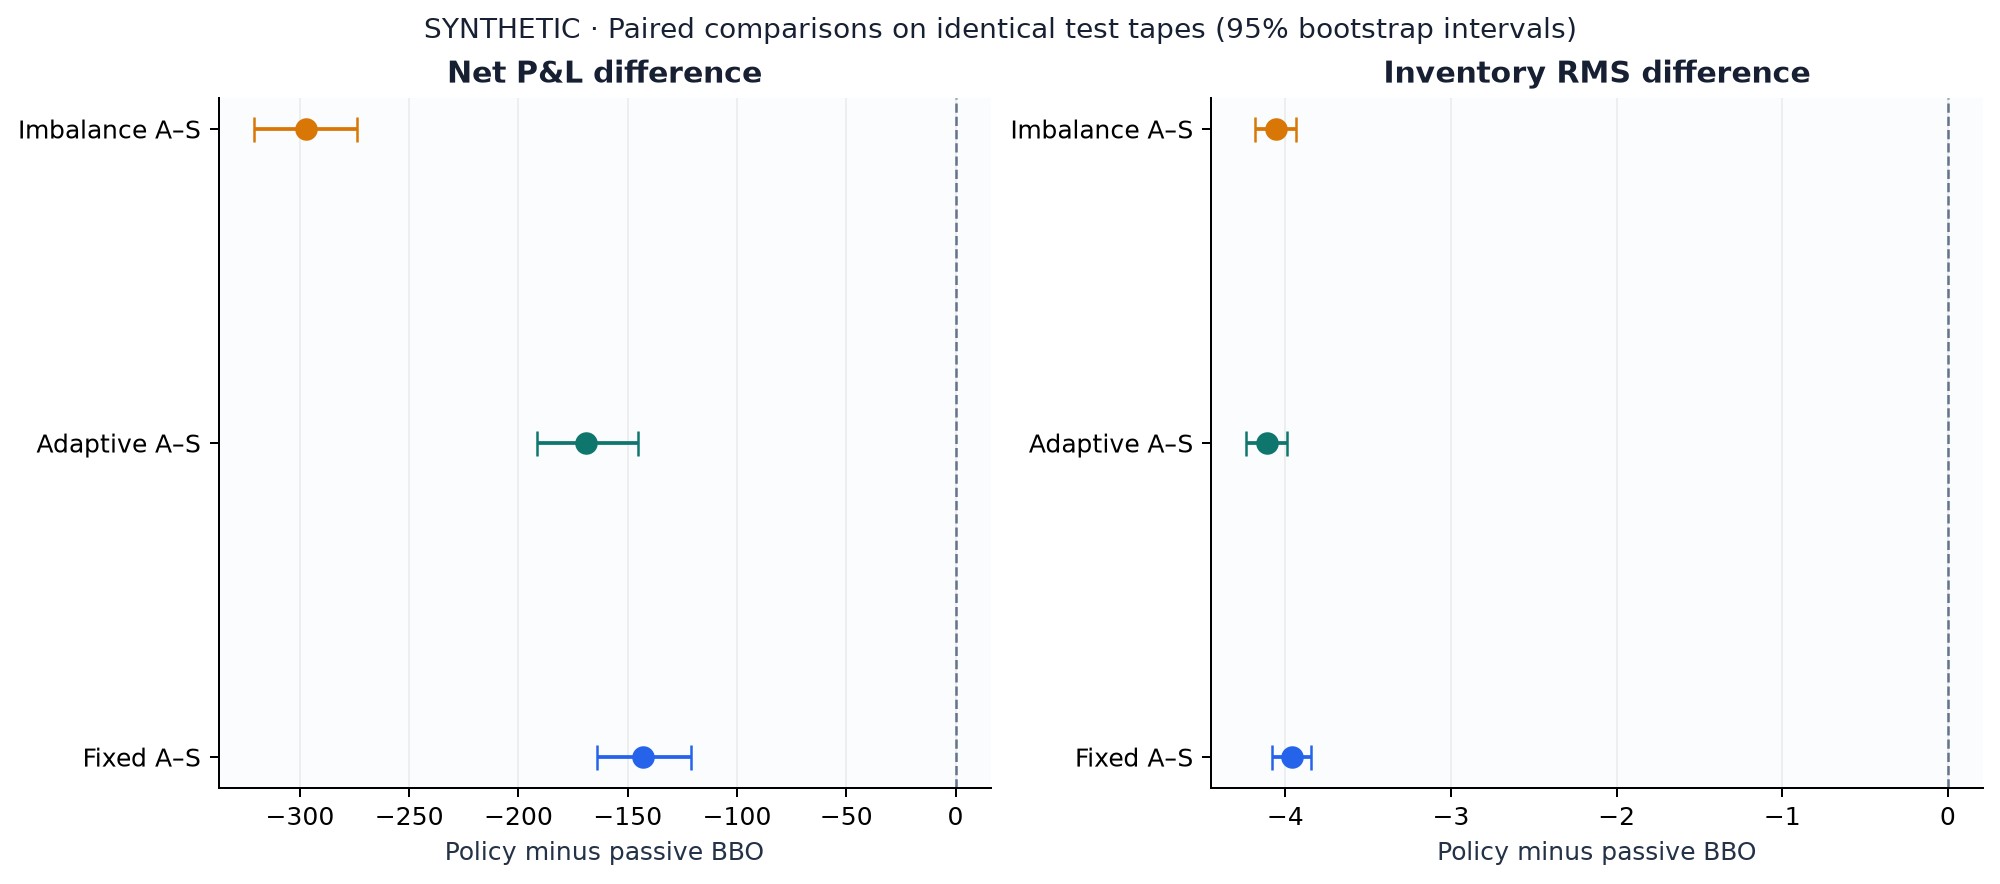

In [5]:
paired = pd.read_csv(ROOT / "results/paired_comparisons.csv")
display(paired[paired.metric == "net_pnl_ticks_lots"].round(3))
display(Image(filename=str(ROOT / "results/figures/03_paired_effects.png"), width=950))

### 5. Change a cost assumption while holding decisions fixed

This model does not feed fees into its quote policy. Its conditional fee sensitivity is therefore algebraic and directly testable: the P&L change equals fee-rate change times maker turnover.

In [6]:
zero = replay(evaluation, "as_adaptive", fit, replace(config, maker_fee_bps=0))
costly = replay(evaluation, "as_adaptive", fit, replace(config, maker_fee_bps=2))
observed_cost = zero.summary["net_pnl_ticks_lots"] - costly.summary["net_pnl_ticks_lots"]
expected_cost = 2 / 10_000 * zero.summary["maker_notional_ticks_lots"]
assert abs(observed_cost - expected_cost) < 1e-7
print(f"Observed two-basis-point cost: {observed_cost:.3f} tick-lots")
print(f"Turnover-based identity: {expected_cost:.3f} tick-lots")

Observed two-basis-point cost: 204.320 tick-lots
Turnover-based identity: 204.320 tick-lots


### 6. Inspect historical evidence separately

Recorded-data values come from Binance Vision and carry CC BY-NC-SA 4.0 attribution as described in `LICENSE-DATA.md`. The table below describes a small set of dependent intraday windows; it is not an IID performance claim.

In [7]:
historical_path = ROOT / "results/historical_break_even.csv"
if historical_path.exists():
    empirical = pd.read_csv(historical_path)
    view = empirical[(empirical.queue == "back") & (empirical.latency == 0.05)]
    display(view[["symbol", "day", "policy", "break_even_maker_fee_bps"]].round(3))
else:
    print("Historical experiment has not been run. Use mm-lab historical explicitly.")

,symbol,day,policy,break_even_maker_fee_bps
0,BTCUSDT,2024-01-01,as_adaptive,-2.298
1,BTCUSDT,2024-01-01,as_fixed,-2.298
2,BTCUSDT,2024-01-01,as_imbalance,-2.219
3,BTCUSDT,2024-01-01,passive,-1.443
16,BTCUSDT,2024-01-02,as_adaptive,-1.317
17,BTCUSDT,2024-01-02,as_fixed,-1.252
18,BTCUSDT,2024-01-02,as_imbalance,-1.158
19,BTCUSDT,2024-01-02,passive,-1.325
32,BTCUSDT,2024-01-03,as_adaptive,-0.380
33,BTCUSDT,2024-01-03,as_fixed,-1.348


### Research extensions to test prospectively

- Choose an inventory-risk budget before comparing policies.
- Change queue assumptions and preserve every scenario, including losses.
- Replace the BBO queue proxy with identified order-level information.
- Extend the frozen time-window protocol across weeks before drawing market-performance conclusions.

The documented contribution is an auditable experimental framework and evidence about its boundaries. The code does not claim a new universal optimal market-making theorem.